# Telco churn: exploratory analysis

This notebook reads the tables built by `src/explore.py` and `src/stat_tests.py` and shows the charts from `src/make_charts.py`. Run `python run_project.py` first so `data/processed/churn_clean.csv` exists. The data is a sample dataset, so findings describe this dataset only, and all differences are associations, not causes.

In [1]:
import sys
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

sys.path.insert(0, str(Path.cwd().parent / 'src'))
import explore
import stat_tests
from config import FIGURES_DIR

pd.set_option('display.width', 200)
df = explore.load_clean()
df.shape

(7043, 25)

## 1. How much churn and how much revenue?

In [2]:
explore.overall_summary(df)

,measure,value
0,customers,7043.00
1,churned_customers,1869.00
2,churn_rate_pct,26.54
3,total_monthly_charges,456116.60
4,monthly_charges_of_churned,139130.85
5,share_of_monthly_charges_lost_pct,30.50
6,avg_monthly_charges_churned,74.44
7,avg_monthly_charges_stayed,61.27


1,869 of 7,043 customers churned (26.54%). Their monthly charges add up to 30.5% of all monthly charges. This is the monthly bill of customers who left, not a forecast of lost profit.

## 2. Churn by customer group

The features are ranked by the gap between their highest and lowest churn group.

In [3]:
by_feature = explore.churn_by_feature(df)
gaps = explore.feature_gaps(by_feature)
gaps[['rank', 'feature', 'highest_group', 'highest_rate_pct', 'lowest_group', 'lowest_rate_pct', 'gap_pct_points']].head(10)

,rank,feature,highest_group,highest_rate_pct,lowest_group,lowest_rate_pct,gap_pct_points
0,1,addon_services,1,45.76,6,5.28,40.48
1,2,contract,Month-to-month,42.71,Two year,2.83,39.88
2,3,tenure_group,0-12 months,47.44,49-72 months,9.51,37.93
3,4,internet_service,Fiber optic,41.89,No,7.40,34.49
4,5,online_security,No,41.77,No internet service,7.40,34.37
5,6,tech_support,No,41.64,No internet service,7.40,34.24
6,7,online_backup,No,39.93,No internet service,7.40,32.53
7,8,device_protection,No,39.13,No internet service,7.40,31.73
8,9,payment_method,Electronic check,45.29,Credit card (automatic),15.24,30.05
9,10,streaming_movies,No,33.68,No internet service,7.40,26.28


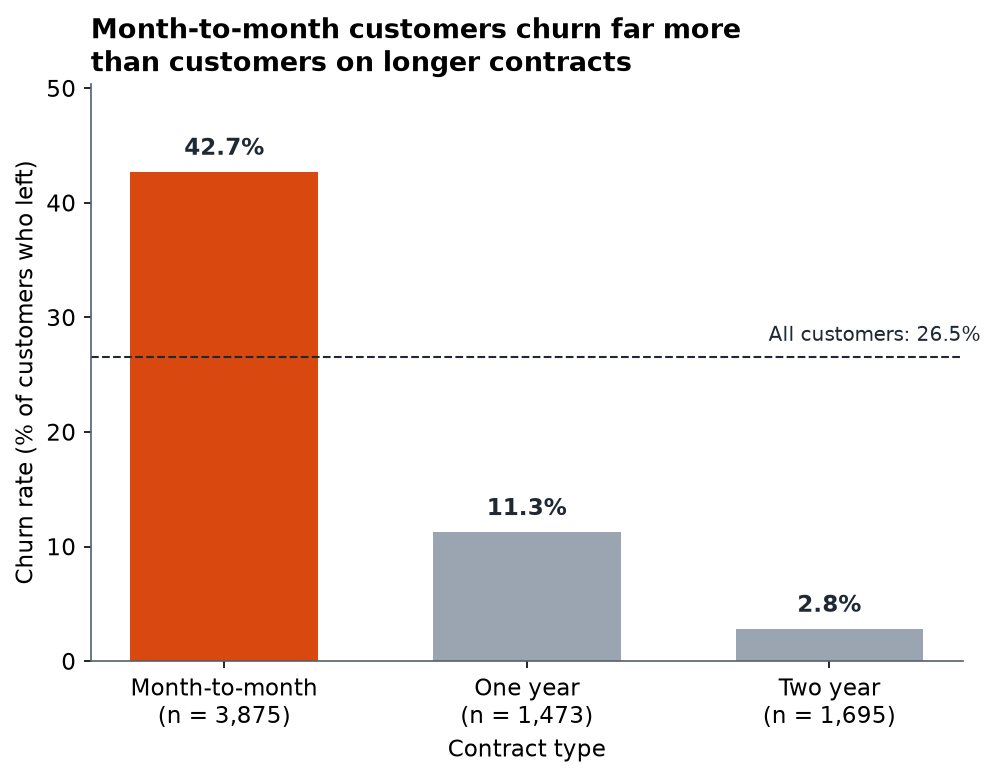

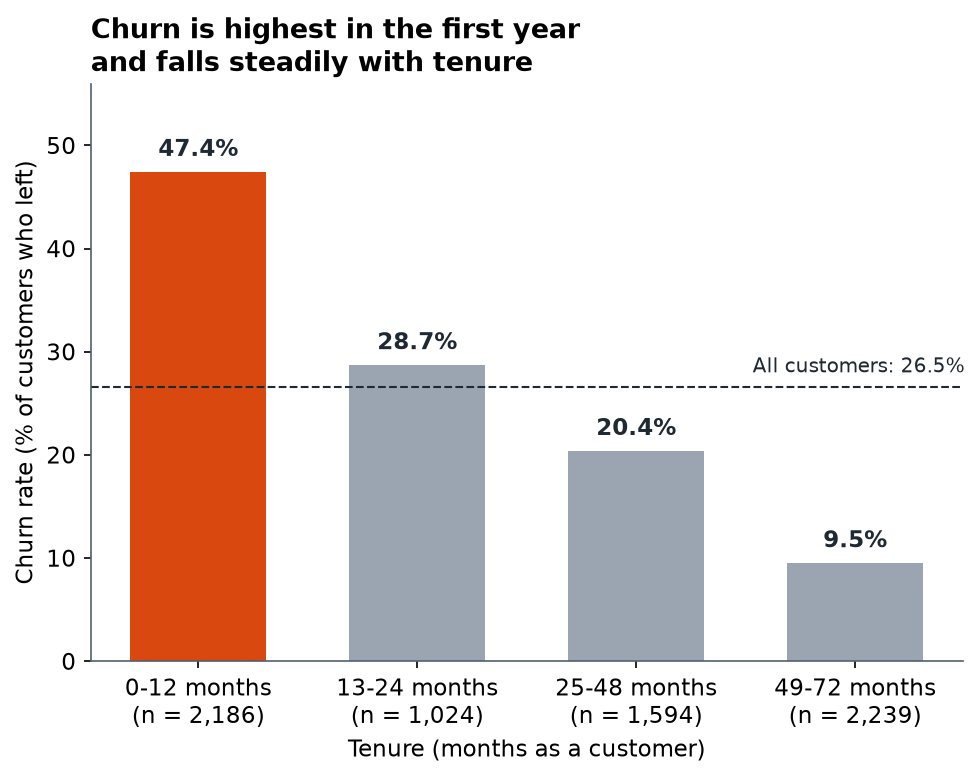

In [4]:
display(Image(FIGURES_DIR / '01_churn_by_contract.png', width=600))
display(Image(FIGURES_DIR / '02_churn_by_tenure.png', width=600))

Month-to-month contracts and the first year of tenure carry the highest churn. Contract and tenure overlap: new customers are more often on month-to-month plans.

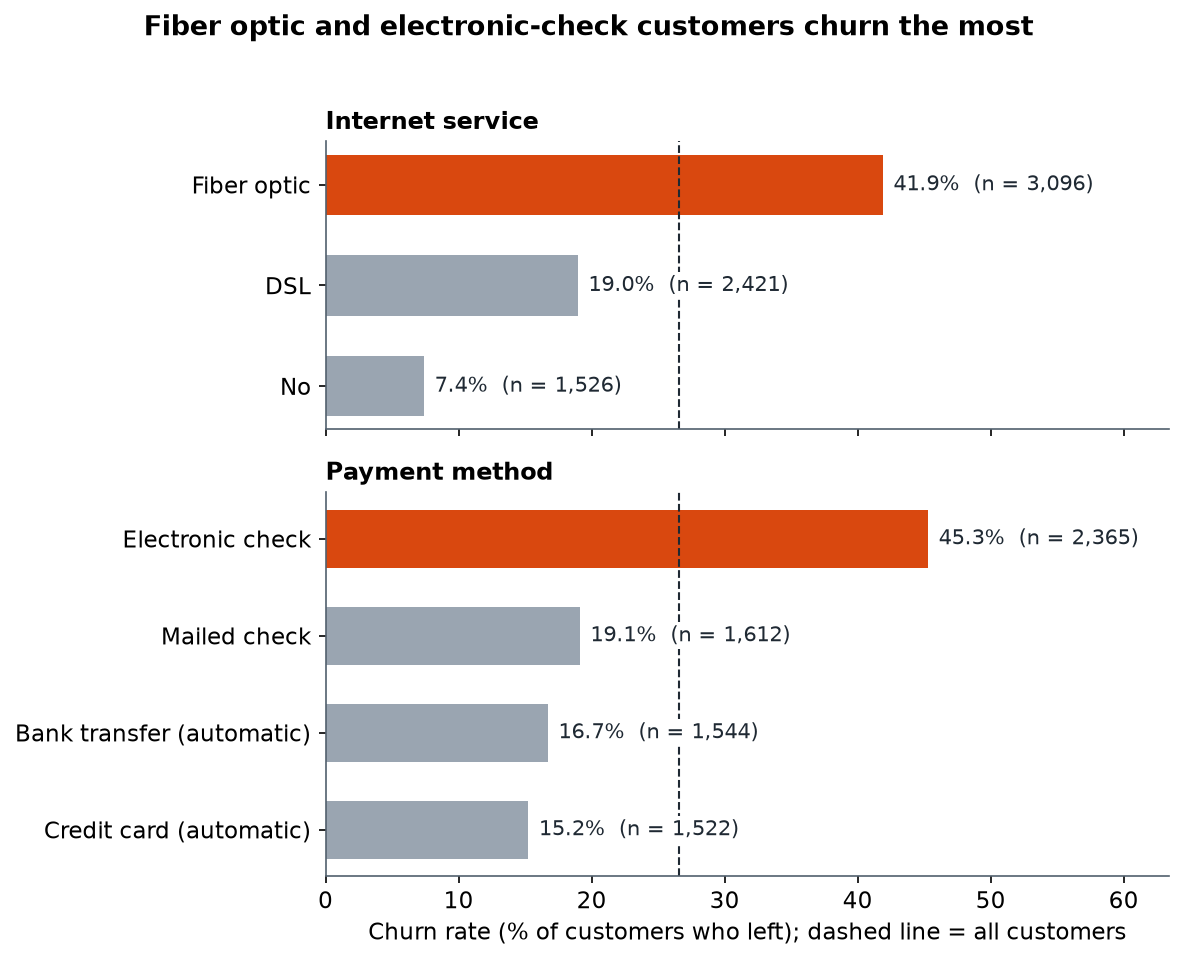

In [5]:
display(Image(FIGURES_DIR / '03_churn_by_internet_and_payment.png', width=650))

## 3. Churned vs stayed: numeric features

In [6]:
explore.numeric_comparison(df)

,feature,group,customers,mean,median
0,tenure_months,churned,1869,17.98,10.00
1,tenure_months,stayed,5174,37.57,38.00
2,monthly_charges,churned,1869,74.44,79.65
3,monthly_charges,stayed,5174,61.27,64.43
4,total_charges,churned,1869,1531.80,703.55
5,total_charges,stayed,5174,2549.91,1679.52


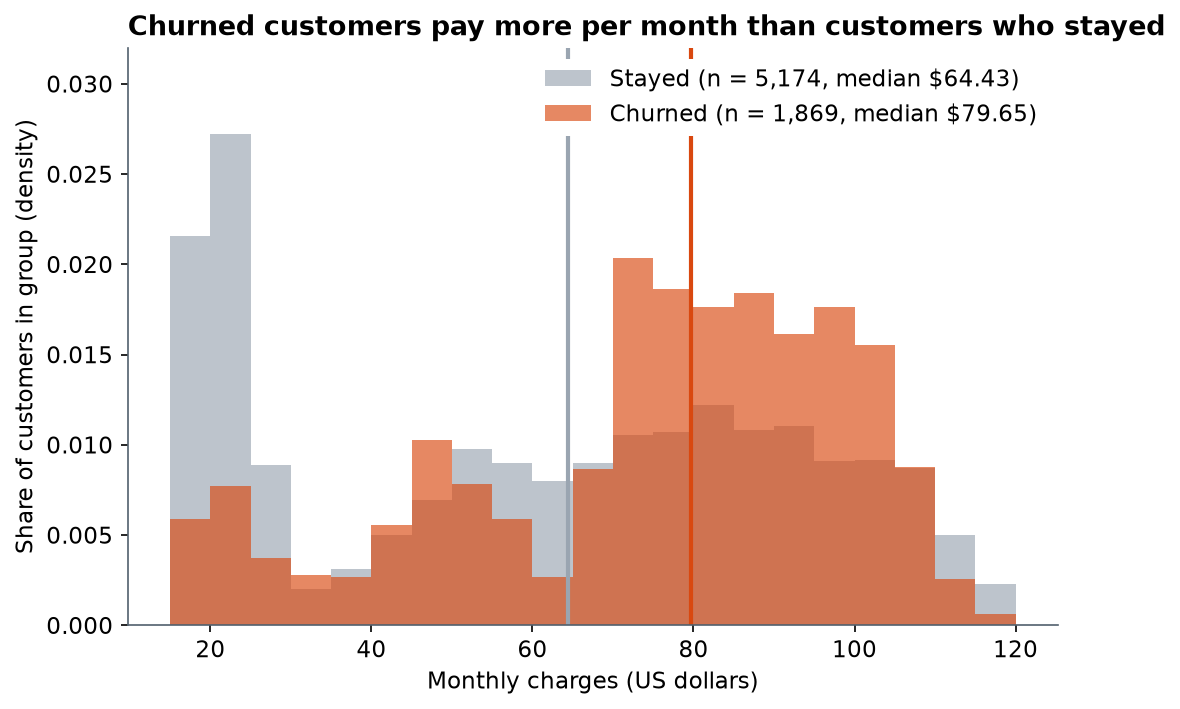

In [7]:
display(Image(FIGURES_DIR / '04_monthly_charges_distribution.png', width=650))

Churned customers have a much shorter tenure (median 10 vs 38 months) and higher monthly charges (median $79.65 vs $64.43).

## 4. Two-way segments

Every cell shows its customer count. Cells under 50 customers would be flagged and get no rate (none occur here).

In [8]:
explore.two_way(df, 'contract', 'internet_service')

,contract,internet_service,customers,churned,churn_rate_pct,small_cell
0,Month-to-month,DSL,1223,394,32.22,False
1,Month-to-month,Fiber optic,2128,1162,54.61,False
2,Month-to-month,No,524,99,18.89,False
3,One year,DSL,570,53,9.30,False
4,One year,Fiber optic,539,104,19.29,False
5,One year,No,364,9,2.47,False
6,Two year,DSL,628,12,1.91,False
7,Two year,Fiber optic,429,31,7.23,False
8,Two year,No,638,5,0.78,False


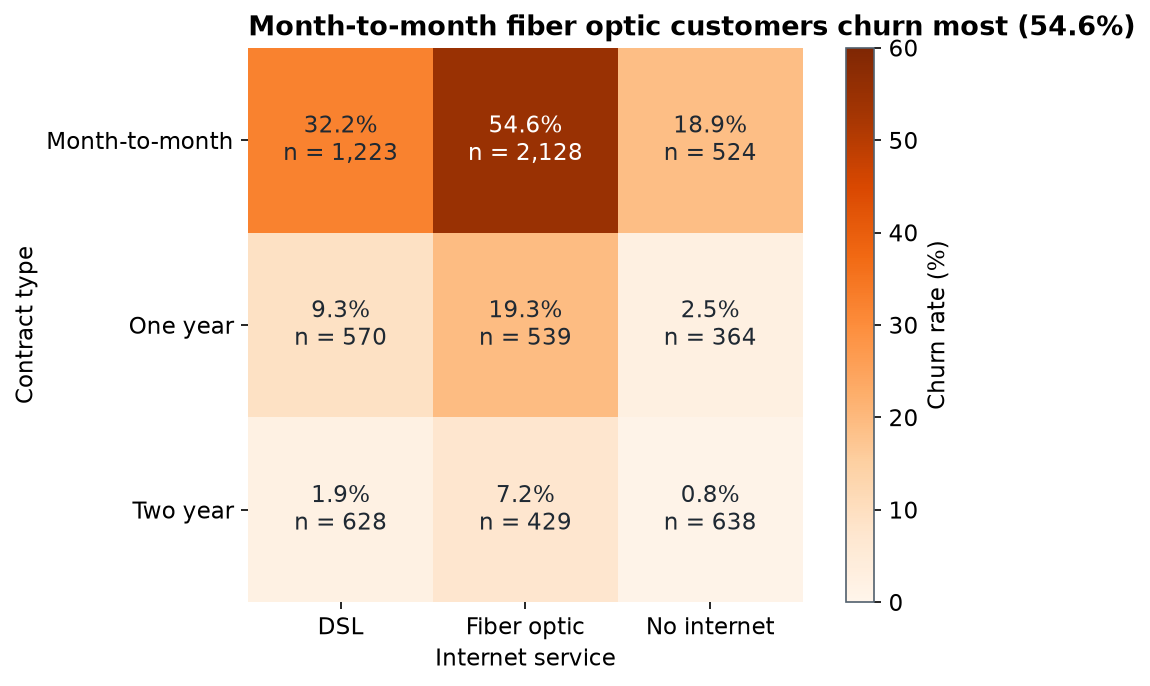

In [9]:
display(Image(FIGURES_DIR / '05_churn_heatmap_contract_internet.png', width=600))

## 5. Highest-risk segments (at least 100 customers)

In [10]:
risk = explore.highest_risk_segments(df)
risk.head(8)

,rank,segment,customers,churned,churn_rate_pct,share_of_churners_pct,share_of_monthly_charges_pct
0,1,contract = Month-to-month & internet_service =...,2128,1162,54.61,62.17,40.60
1,2,internet_service = Fiber optic & payment_metho...,1595,849,53.23,45.43,31.36
2,3,contract = Month-to-month & tenure_group = 0-1...,1994,1024,51.35,54.79,25.45
3,4,tenure_group = 0-12 months,2186,1037,47.44,55.48,26.89
4,5,addon_services = 1,966,442,45.76,23.65,13.89
5,6,payment_method = Electronic check,2365,1071,45.29,57.30,39.54
6,7,contract = Month-to-month,3875,1655,42.71,88.55,56.41
7,8,internet_service = Fiber optic & payment_metho...,258,110,42.64,5.89,4.89


## 6. Statistical tests

With 7,043 customers even small differences give tiny p-values, so the effect size (Cramér's V, rank-biserial) is the more useful column. P-values are Holm-adjusted because 21 tests were run.

In [11]:
tests = stat_tests.run_tests(df)
tests[['rank', 'feature', 'test', 'p_holm', 'effect_size', 'effect_label', 'significant_after_holm']]

,rank,feature,test,p_holm,effect_size,effect_label,significant_after_holm
0,1,tenure_months,mann-whitney-u,4.839271e-207,-0.479734,medium,True
1,2,contract,chi-square,1.231238e-256,0.410116,medium,True
2,3,tenure_group,chi-square,5.298787e-184,0.348645,medium,True
3,4,online_security,chi-square,5.056184e-184,0.347400,medium,True
4,5,tech_support,chi-square,2.453243e-179,0.342916,medium,True
5,6,internet_service,chi-square,1.531486e-158,0.322455,medium,True
6,7,payment_method,chi-square,5.523532e-139,0.303359,medium,True
7,8,total_charges,mann-whitney-u,6.822041e-82,-0.300692,medium,True
8,9,online_backup,chi-square,2.911663e-130,0.292316,small,True
9,10,device_protection,chi-square,7.156785e-121,0.281580,small,True


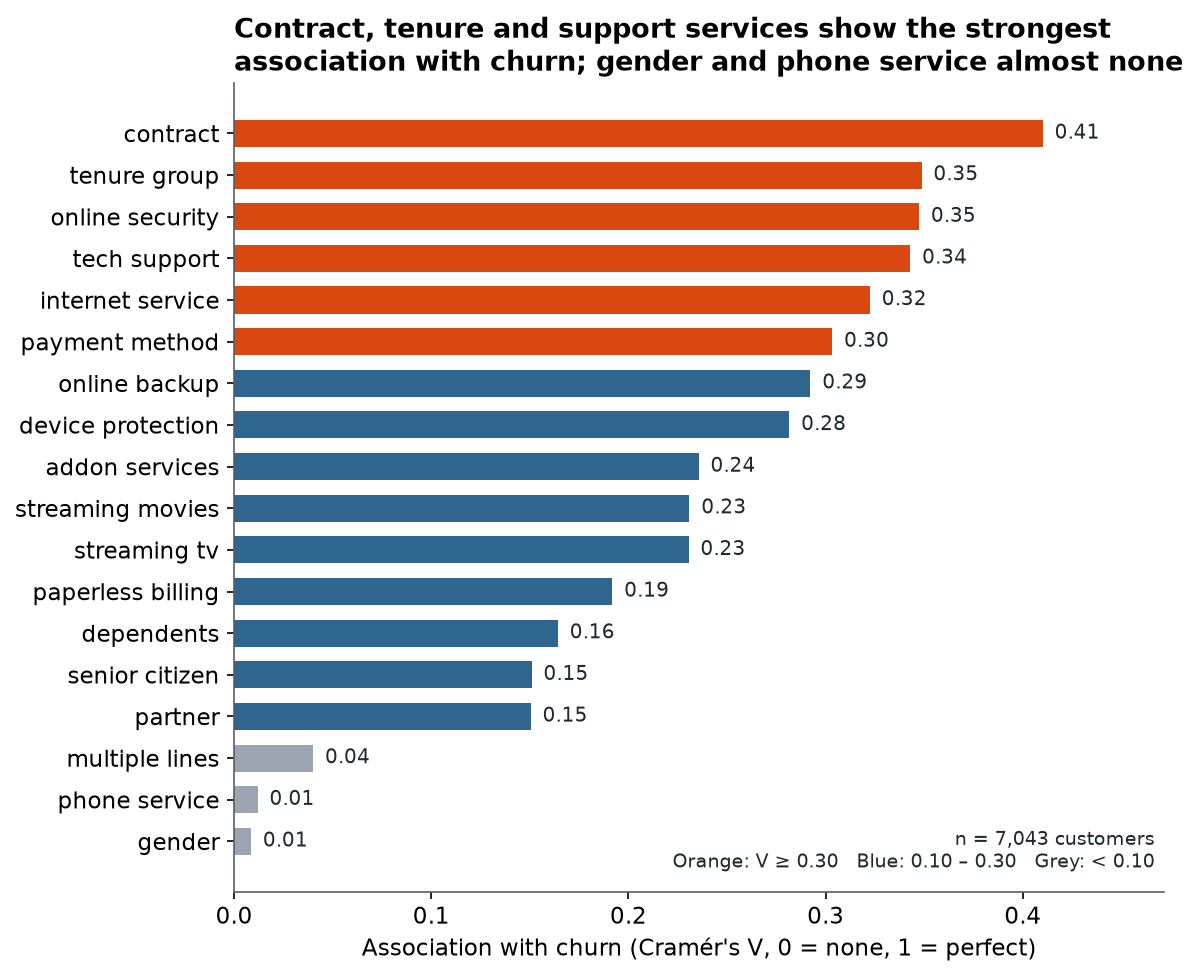

In [12]:
display(Image(FIGURES_DIR / '06_feature_association_ranking.png', width=600))

Contract, tenure, internet service, payment method, online security and tech support show the largest associations. Gender and phone service show none that survives correction. These results are the base for the prediction models on Day 3.